In [ ]:
# 10/31 작업 - hatching

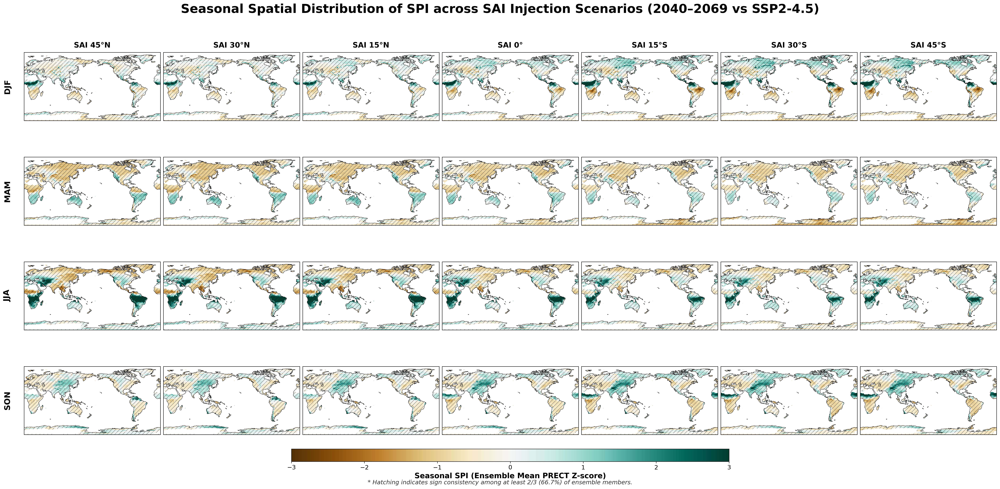

In [23]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from global_land_mask import globe

# 마스킹(pdf와 동일)

ds_ssp = xr.open_dataset('PR_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
    arr = ds_ssp[v].squeeze()
    if arr.ndim == 2 and arr.shape == (192, 288):
        ssp_mean_grid = arr.values
        break
if ssp_mean_grid is None:
    ssp_mean_grid = ds_ssp[list(ds_ssp.data_vars)[0]].squeeze().values

lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)
lons = ds_ssp['lon'].values

lons_180 = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

# 육지 및 사막 제외 조건

is_land = globe.is_land(lat_grid, lon_grid)
mean_val = np.nanmean(ssp_mean_grid)
arid_threshold = 2.315e-6 if mean_val > 1e-6 else 2.315e-9
is_not_arid = (ssp_mean_grid >= arid_threshold)

valid_mask = is_land & is_not_arid  # Shape: (192, 288)

lat_scenarios = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']
lat_titles = ['45°N', '30°N', '15°N', '0°', '15°S', '30°S', '45°S']
ensembles = ['e02', 'e03', 'e04', 'e05', 'e06', 'e07']
seasons = ['DJF', 'MAM', 'JJA', 'SON']

fig, axes = plt.subplots(
    nrows=4, ncols=7, figsize=(28, 13), dpi=300,
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)},
    constrained_layout=True
)

fig.suptitle(
    'Seasonal Spatial Distribution of SPI across SAI Injection Scenarios (2040–2069 vs SSP2-4.5)',
    fontsize=25, fontweight='bold', y=1.03
)

im = None  # Colorbar 연동용 변수

# Hatching 굵기 조절

plt.rcParams['hatch.linewidth'] = 0.4
plt.rcParams['hatch.color'] = '#333333'

for col_idx, lat_str in enumerate(lat_scenarios):
    # 6개 앙상블 멤버 파일 로드 -> Stack Shape: (6, 4, 192, 288)
    ens_data_list = []
    for ens in ensembles:
        file_path = f"PR_zscore_yseasmean_{lat_str}_{ens}.nc"
        ds = xr.open_dataset(file_path)
        
        # (192, 288) 공간 격자를 가진 3D 배열 (4, 192, 288) 추출
        z_arr = None
        for v in ds.data_vars:
            arr = ds[v].squeeze()
            if arr.ndim == 3 and arr.shape[-2:] == (192, 288):
                z_arr = arr.values
                break
        if z_arr is None:
            var_key = 'pr' if 'pr' in ds else list(ds.data_vars)[0]
            z_arr = ds[var_key].squeeze().values
            
        ens_data_list.append(z_arr)
        
    ens_data_stack = np.stack(ens_data_list, axis=0)  # (6, 4, 192, 288)
    ens_mean = np.mean(ens_data_stack, axis=0)        # 앙상블 평균 (4, 192, 288)

    for row_idx, season in enumerate(seasons):
        ax = axes[row_idx, col_idx]
        
        season_stack = ens_data_stack[:, row_idx, :, :]
        season_mean = ens_mean[row_idx]
        
        # hatching이 들어갈 구역 마스킹
        
        pos_count = np.sum(season_stack > 0, axis=0)  # 양수 변화 멤버 수
        neg_count = np.sum(season_stack < 0, axis=0)  # 음수 변화 멤버 수
        max_agree_ratio = np.maximum(pos_count, neg_count) / len(ensembles)
        
        # 2/3 일치 조건
        
        hatch_mask = (max_agree_ratio >= (2/3)) & valid_mask  # Shape: (192, 288)
        
        season_mean_masked = np.where(valid_mask, season_mean, np.nan)
        season_mean_clipped = np.clip(season_mean_masked, -3.0, 3.0)
        
        im = ax.pcolormesh(
            lons, lats, season_mean_clipped,
            transform=ccrs.PlateCarree(),
            cmap='BrBG', vmin=-3.0, vmax=3.0
        )
        
        ax.contourf(
            lons, lats, hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=['///'],
            colors='none',
            transform=ccrs.PlateCarree()
        )
        
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')
        
        # Subplot 라벨
        
        if row_idx == 0:
            ax.set_title(f"SAI {lat_titles[col_idx]}", fontsize=15, fontweight='bold', pad=10)
        if col_idx == 0:
            ax.text(-0.15, 0.5, season, transform=ax.transAxes,
                    fontsize=16, fontweight='bold', va='center', rotation=90)

# 하단 colorbar

cbar = fig.colorbar(
    im, ax=axes, orientation='horizontal', 
    shrink=0.45, aspect=35, pad=0.03
)
cbar.set_label('Seasonal SPI (Ensemble Mean PRECT Z-score)', fontsize=15, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

fig.text(
    0.5, -0.01, 
    '* Hatching indicates sign consistency among at least 2/3 (66.7%) of ensemble members.',
    ha='center', fontsize=12, fontstyle='italic', color='#333333'
)

plt.savefig('SPI_4x7_ensemble_hatched_map.png', dpi=300, bbox_inches='tight')
plt.show()

[Warning] File not found, skipping: AET_zscore_yseasmean_15N_e05.nc


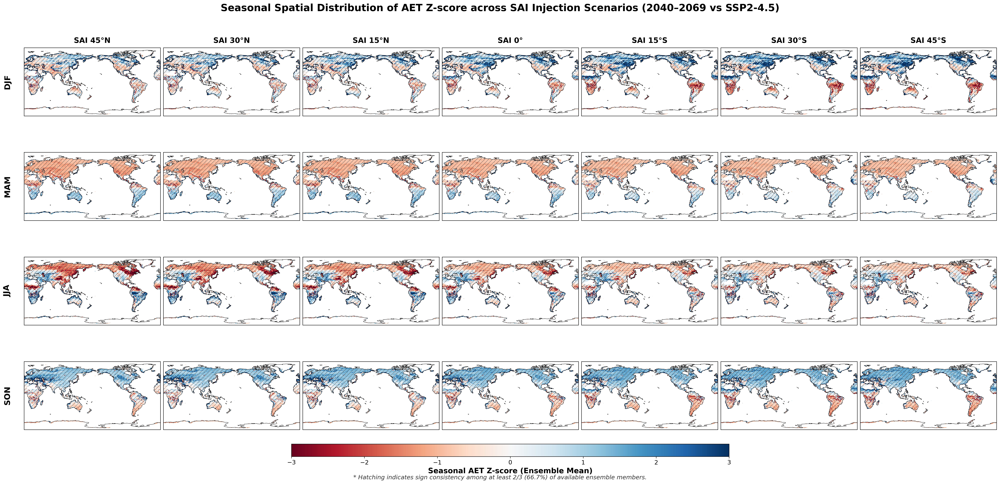

In [22]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from global_land_mask import globe

# 마스킹(aet z-score pdf와 동일)

ds_ssp = xr.open_dataset('AET_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
    arr = ds_ssp[v].squeeze()
    if arr.ndim == 2 and arr.shape == (192, 288):
        ssp_mean_grid = arr.values
        break
if ssp_mean_grid is None:
    ssp_mean_grid = ds_ssp[list(ds_ssp.data_vars)[0]].squeeze().values

lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)
lons = ds_ssp['lon'].values

lons_180 = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

# 육지 & 비활성 식생/사막/영구빙설 제외

is_land = globe.is_land(lat_grid, lon_grid)
is_active_et = (ssp_mean_grid >= 0.15)

valid_mask = is_land & is_active_et  # Shape: (192, 288)

lat_scenarios = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']
lat_titles = ['45°N', '30°N', '15°N', '0°', '15°S', '30°S', '45°S']
ensembles = ['e02', 'e03', 'e04', 'e05', 'e06', 'e07']
seasons = ['DJF', 'MAM', 'JJA', 'SON']

fig, axes = plt.subplots(
    nrows=4, ncols=7, figsize=(28, 13), dpi=300,
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)},
    constrained_layout=True
)

fig.suptitle(
    'Seasonal Spatial Distribution of AET Z-score across SAI Injection Scenarios (2040–2069 vs SSP2-4.5)',
    fontsize=20, fontweight='bold', y=1.02
)

im = None  # Colorbar 연동용 변수

# Hatching 굵기 조절

plt.rcParams['hatch.linewidth'] = 0.4
plt.rcParams['hatch.color'] = '#333333'

for col_idx, lat_str in enumerate(lat_scenarios):

    ens_data_list = []
    for ens in ensembles:
        file_path = f"AET_zscore_yseasmean_{lat_str}_{ens}.nc"
        
        # 15N e05 누락으로 인해, 파일 없을시 스킵하는 코드
        if not os.path.exists(file_path):
            print(f"[Warning] File not found, skipping: {file_path}")
            continue
            
        ds = xr.open_dataset(file_path)
        
        # (192, 288) 공간 격자를 가진 3D 배열 (4, 192, 288) 추출
        
        z_arr = None
        for v in ds.data_vars:
            arr = ds[v].squeeze()
            if arr.ndim == 3 and arr.shape[-2:] == (192, 288):
                z_arr = arr.values
                break
        if z_arr is None:
            var_key = 'aet' if 'aet' in ds else list(ds.data_vars)[0]
            z_arr = ds[var_key].squeeze().values
            
        ens_data_list.append(z_arr)
        
    if len(ens_data_list) == 0:
        print(f"[Error] No ensemble files found for latitude {lat_str}")
        continue
        
    ens_data_stack = np.stack(ens_data_list, axis=0)  # Shape: (N_valid_ens, 4, 192, 288)
    n_valid_ens = len(ens_data_list)
    ens_mean = np.mean(ens_data_stack, axis=0)        # 앙상블 평균 (4, 192, 288)

    for row_idx, season in enumerate(seasons):
        ax = axes[row_idx, col_idx]
        
        season_stack = ens_data_stack[:, row_idx, :, :]
        season_mean = ens_mean[row_idx]
        
        # hatching 들어갈 지역 골라서 마스킹
        
        pos_count = np.sum(season_stack > 0, axis=0)  # 양수 변화 멤버 수
        neg_count = np.sum(season_stack < 0, axis=0)  # 음수 변화 멤버 수
        max_agree_ratio = np.maximum(pos_count, neg_count) / n_valid_ens
        
        # 2/3 이상 일치 조건
        
        hatch_mask = (max_agree_ratio >= (2/3)) & valid_mask  # Shape: (192, 288)
        
        season_mean_masked = np.where(valid_mask, season_mean, np.nan)
        season_mean_clipped = np.clip(season_mean_masked, -3.0, 3.0)
        
        im = ax.pcolormesh(
            lons, lats, season_mean_clipped,
            transform=ccrs.PlateCarree(),
            cmap='RdBu', vmin=-3.0, vmax=3.0
        )
        
        ax.contourf(
            lons, lats, hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=['///'],
            colors='none',
            transform=ccrs.PlateCarree()
        )
        
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')
        
        # Subplot 라벨
        
        if row_idx == 0:
            ax.set_title(f"SAI {lat_titles[col_idx]}", fontsize=15, fontweight='bold', pad=10)
        if col_idx == 0:
            ax.text(-0.15, 0.5, season, transform=ax.transAxes,
                    fontsize=16, fontweight='bold', va='center', rotation=90)

# 하단 colorbar

cbar = fig.colorbar(
    im, ax=axes, orientation='horizontal', 
    shrink=0.45, aspect=35, pad=0.03
)
cbar.set_label('Seasonal AET Z-score (Ensemble Mean)', fontsize=15, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

fig.text(
    0.5, -0.01, 
    '* Hatching indicates sign consistency among at least 2/3 (66.7%) of available ensemble members.',
    ha='center', fontsize=12, fontstyle='italic', color='#333333'
)

plt.savefig('AET_4x7_ensemble_hatched_map.png', dpi=300, bbox_inches='tight')
plt.show()